# Pregunta 1 · Clasificación de recortes de Quirpinchaca

Dividí cada fotografía de los dos datasets en 16 recortes RGB de 128 × 128 píxeles. Separé las fotografías en 80 % para entrenamiento y 20 % para prueba, manteniendo juntos los recortes de cada original. Con K-Means agrupé los recortes de entrenamiento por semejanza visual y examiné la inercia y la silueta. Etiqueté representantes como suelo, basura o planta y propagué esas etiquetas dentro de cada grupo para entrenar una regresión logística. Después revisé ejemplos de baja confianza y volví a ajustar el clasificador. Comparé los modelos sobre los mismos recortes de prueba etiquetados manualmente mediante exactitud y analicé los errores del modelo activo con una matriz de confusión.

## 1. Abrir las dos carpetas

Se incluyen los formatos de imagen, entre ellos los HEIC de la primera carpeta. Comprueba los conteos impresos.

In [1]:
from pathlib import Path
from collections import Counter
import csv
import hashlib
import json
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from pillow_heif import register_heif_opener
def clear_output(wait=True):
    from IPython.display import clear_output as limpiar_salida
    limpiar_salida(wait=wait)
from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import silhouette_samples, silhouette_score, accuracy_score, ConfusionMatrixDisplay

register_heif_opener()
SEMILLA = 42
CLASES = ["suelo", "basura", "planta"]

RAIZ = Path(r"C:\Users\HP\Desktop\UNI\7moo SEMESTRE\SIS420 INTELIGENCIA ARTIFICIAL\SIS420 INTELIGENCIA ARTIFICIAL\PARCIALES\2DO PARCIAL\PREGUNTA1\DATASET")
carpetas = ["dataset quirpinchaca 02", "dataset quirpinchaca 03"]
extensiones = {".jpg", ".jpeg", ".png", ".heic", ".heif"}
fotos = []
for carpeta in carpetas:
    directorio = RAIZ / carpeta
    if not directorio.is_dir():
        raise FileNotFoundError(f"Revisa la ruta de la carpeta: {directorio}")
    imagenes = sorted(p for p in directorio.rglob("*") if p.is_file() and p.suffix.lower() in extensiones)
    if not imagenes:
        raise ValueError(f"No se encontraron imágenes en {directorio}")
    fotos.extend(imagenes)
    print(carpeta, len(imagenes), dict(Counter(p.suffix.lower() for p in imagenes)))

firma = hashlib.sha256(json.dumps([(p.relative_to(RAIZ).as_posix(),p.stat().st_size,p.stat().st_mtime_ns)
                                   for p in fotos]).encode()).hexdigest()[:12]
ruta_etiquetas = RAIZ.parent / f"anotaciones_RGB128_{firma}.csv"
def escribir_csv(ruta, datos, campos):
    temporal = ruta.with_suffix(".tmp")
    with temporal.open("w", newline="", encoding="utf-8-sig") as archivo:
        escritor = csv.DictWriter(archivo, fieldnames=campos)
        escritor.writeheader()
        escritor.writerows(datos)
    temporal.replace(ruta)

dataset quirpinchaca 02 369 {'.jpeg': 64, '.heic': 156, '.jpg': 149}
dataset quirpinchaca 03 194 {'.jpg': 194}


## 2. Obtener los 16 recortes RGB

Se recorre cada original una vez. Los límites de las cuatro filas y cuatro columnas incluyen los bordes de la foto. Un vector normalizado solo se construye cuando se necesita.

In [2]:
imagenes = np.empty((16*len(fotos),128,128,3),dtype=np.uint8)
filas = []
for numero,ruta in enumerate(fotos):
    relativa = ruta.relative_to(RAIZ)
    with Image.open(ruta) as original:
        foto = ImageOps.exif_transpose(original).convert("RGB")
    with foto:
        w,h = foto.size
        for j in range(16):
            f,c = divmod(j,4)
            caja = (c*w//4,f*h//4,(c+1)*w//4,(f+1)*h//4)
            with foto.crop(caja) as region:
                with region.resize((128,128),Image.Resampling.LANCZOS) as recorte:
                    imagenes[16*numero+j] = np.asarray(recorte)
            filas.append(dict(ruta_original=relativa.as_posix(),origen=relativa.parts[0],
                              ruta_recorte=f"{relativa.as_posix()}#r{j+1:02d}"))
    if (numero+1)%50==0: print(numero+1,"/",len(fotos))
def vectores(ids):
    pixeles = imagenes[np.asarray(ids,dtype=int)]
    return pixeles.reshape(len(pixeles),128*128*3).astype(np.float32)/255
print("Recortes y dimensiones RGB",imagenes.shape)

50 / 563
100 / 563
150 / 563
200 / 563
250 / 563
300 / 563
350 / 563
400 / 563
450 / 563
500 / 563
550 / 563
Recortes y dimensiones RGB (9008, 128, 128, 3)


## 3. Separar 80 % train y 20 % test

Los 16 recortes de un archivo original permanecen juntos. Dos archivos distintos pueden contener la misma escena. La figura ilustra el troceado con una fotografía de train.

train 450 fotografías 7200 recortes
test 113 fotografías 1808 recortes


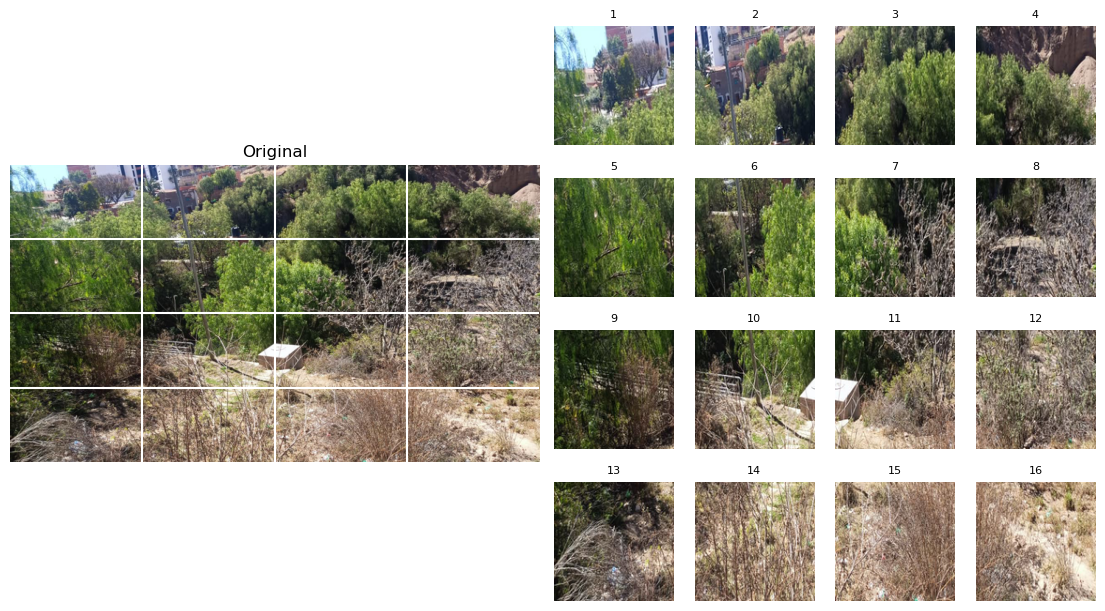

In [3]:
originales = sorted({r["ruta_original"] for r in filas})
orig_train, orig_test = train_test_split(originales,test_size=0.20,random_state=SEMILLA)
orig_test = set(orig_test)
for r in filas:
    r["particion"] = "test" if r["ruta_original"] in orig_test else "train"
train = [i for i,r in enumerate(filas) if r["particion"]=="train"]
test = [i for i,r in enumerate(filas) if r["particion"]=="test"]
assert set(orig_train).isdisjoint(orig_test)

for nombre,ids in [("train",train),("test",test)]:
    print(nombre,len(ids)//16,"fotografías",len(ids),"recortes")
ejemplo = train[0]//16
fig = plt.figure(figsize=(11,6),constrained_layout=True)
grilla = fig.add_gridspec(4,8)
ax = fig.add_subplot(grilla[:,:4])
with Image.open(fotos[ejemplo]) as im:
    vista = ImageOps.exif_transpose(im).convert("RGB")
vista.thumbnail((720,720))
ax.imshow(vista)
for j in (1,2,3):
    ax.axvline(vista.width*j/4-.5,color="white")
    ax.axhline(vista.height*j/4-.5,color="white")
ax.axis("off")
ax.set_title("Original")
for j in range(16):
    f,c = divmod(j,4)
    ax = fig.add_subplot(grilla[f,c+4])
    ax.imshow(imagenes[16*ejemplo+j])
    ax.set_title(str(j+1),fontsize=8)
    ax.axis("off")
plt.show()

## 4. K-Means y centroides en color

K=15 reproduce el presupuesto del Lab 07. Un grupo describe semejanza visual. La etiqueta semántica se asigna después. predict elige el centro más cercano y transform devuelve las distancias a todos los centros.

Grupos [1 2 8 8]
Distancias del primer recorte [62.9  47.53 52.28 58.92 78.17 70.27 51.65 56.42 64.67 69.4  58.11 78.56
 75.45 62.35 64.86]


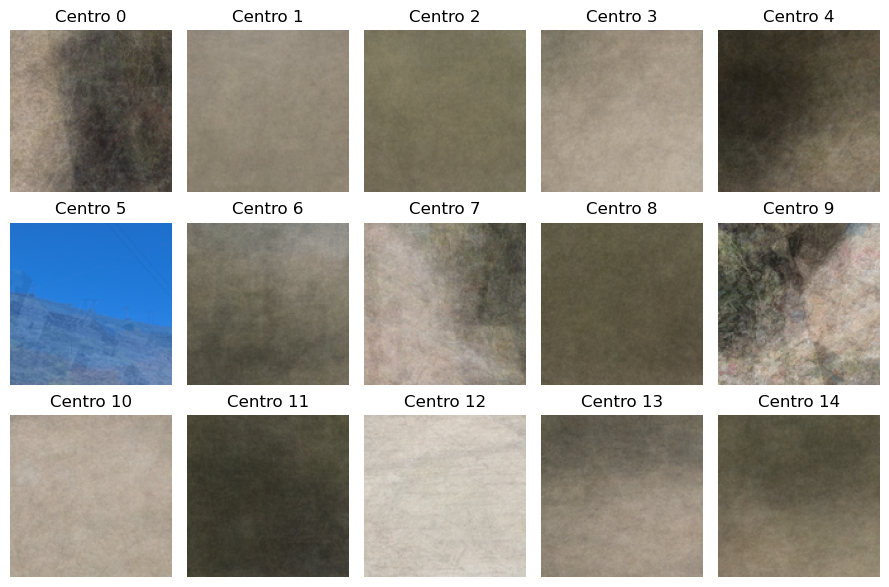

In [4]:
k = 15
ids_muestra = np.random.RandomState(SEMILLA).choice(train,min(1000,len(train)),replace=False)
X_muestra = vectores(ids_muestra)
kmeans = KMeans(n_clusters=k,n_init=1,random_state=SEMILLA).fit(X_muestra)
distancias = np.empty((len(train),k),dtype=np.float32)
for inicio in range(0,len(train),64):
    lote = train[inicio:inicio+64]
    distancias[inicio:inicio+len(lote)] = kmeans.transform(vectores(lote))
grupos_train = distancias.argmin(axis=1)
print("Grupos",kmeans.predict(vectores(train[:4])))
print("Distancias del primer recorte",distancias[0].round(2))
fig,ejes = plt.subplots(3,5,figsize=(9,6))
for g,ax in enumerate(ejes.flat):
    ax.imshow(kmeans.cluster_centers_[g].reshape(128,128,3).clip(0,1))
    ax.set_title(f"Centro {g}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 5. Visualización 2D, iteraciones e inicialización

Se reproduce la demostración de tu Lab 07 sobre una proyección PCA de la muestra. El K-Means principal y los clasificadores siguen usando todos los píxeles RGB.

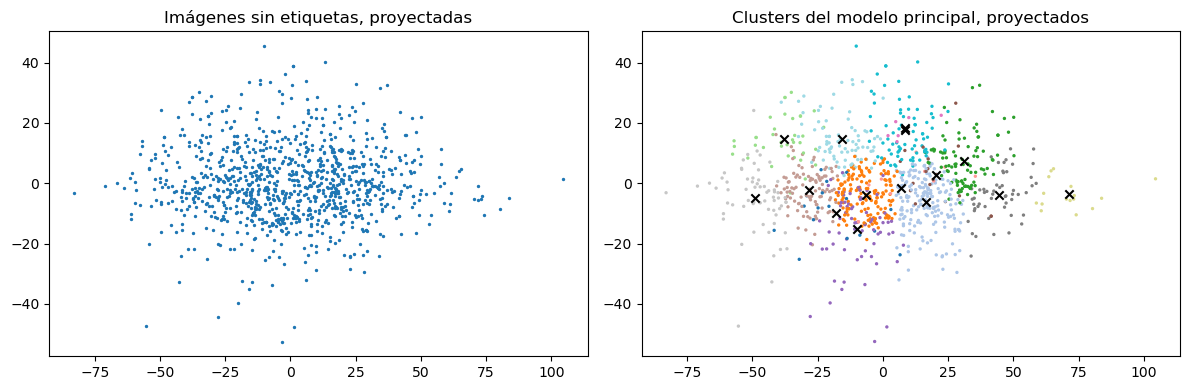

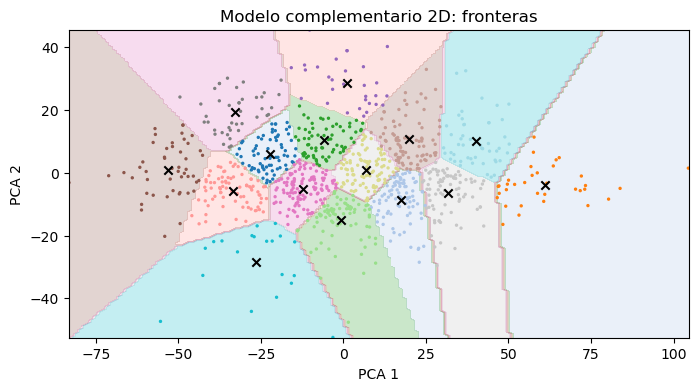

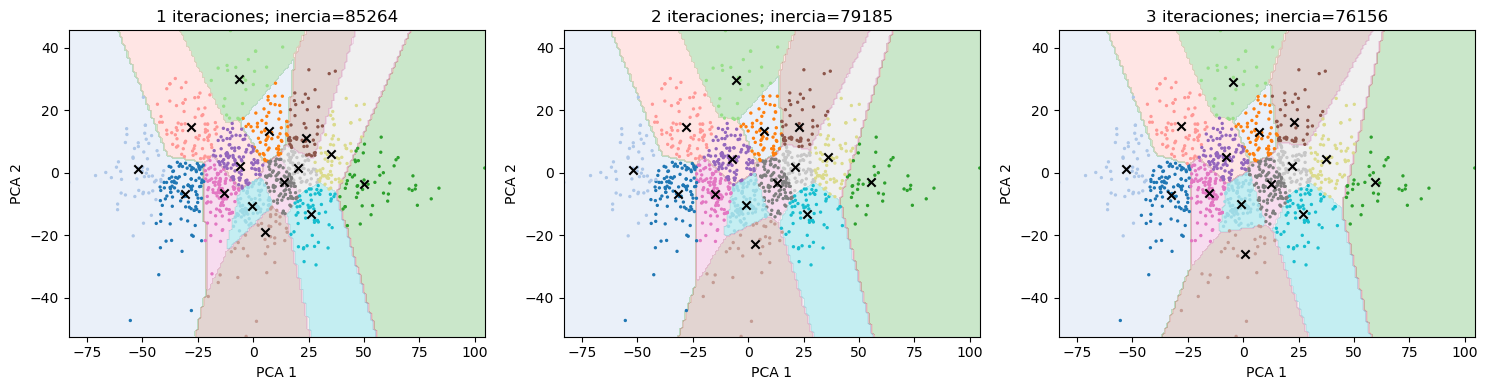

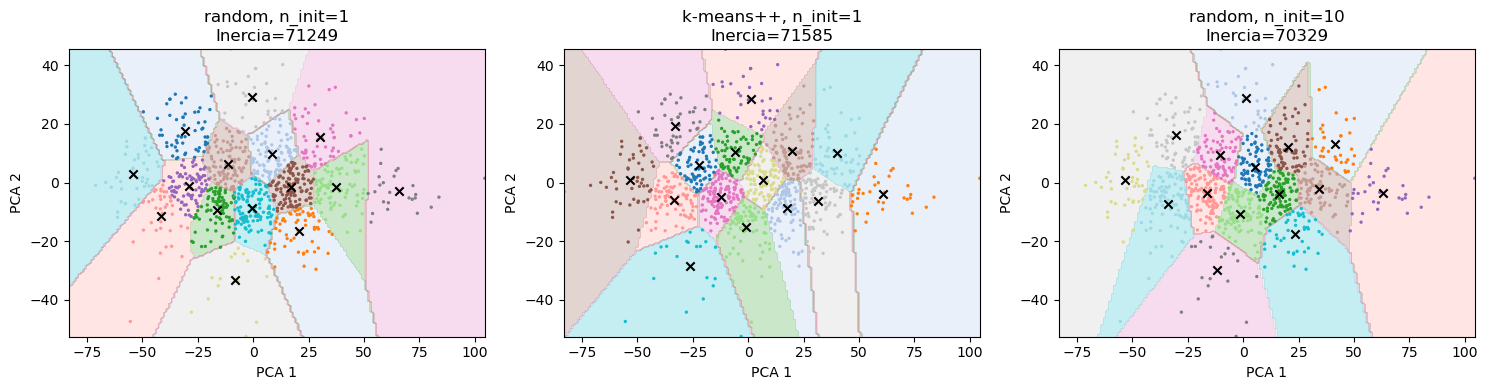

In [5]:
from sklearn.decomposition import PCA
pca_visual = PCA(n_components=2, random_state=SEMILLA)
Z = pca_visual.fit_transform(X_muestra)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(Z[:, 0], Z[:, 1], s=2)
axes[0].set_title('Imágenes sin etiquetas, proyectadas')
axes[1].scatter(Z[:, 0], Z[:, 1], c=kmeans.labels_, s=2, cmap='tab20')
centros = pca_visual.transform(kmeans.cluster_centers_)
axes[1].scatter(centros[:, 0], centros[:, 1], marker='x', c='black')
axes[1].set_title('Clusters del modelo principal, proyectados')
plt.tight_layout(); plt.show()

def fronteras_2d(modelo, ax, titulo):
    minimo, maximo = Z.min(axis=0) - 0.1, Z.max(axis=0) + 0.1
    xx, yy = np.meshgrid(np.linspace(minimo[0], maximo[0], 160),
                         np.linspace(minimo[1], maximo[1], 160))
    pred = modelo.predict(np.column_stack([xx.ravel(), yy.ravel()])).reshape(xx.shape)
    ax.contourf(xx, yy, pred, alpha=0.25, cmap='tab20')
    ax.scatter(Z[:, 0], Z[:, 1], c=modelo.labels_, s=2, cmap='tab20')
    ax.scatter(modelo.cluster_centers_[:, 0], modelo.cluster_centers_[:, 1], marker='x', c='black')
    ax.set_title(titulo); ax.set_xlabel('PCA 1'); ax.set_ylabel('PCA 2')
modelo_visual = KMeans(n_clusters=k, n_init=1, random_state=SEMILLA).fit(Z)
fig, ax = plt.subplots(figsize=(8, 4))
fronteras_2d(modelo_visual, ax, 'Modelo complementario 2D: fronteras')
plt.show()

centros_iniciales = Z[np.random.RandomState(SEMILLA).choice(len(Z), k, replace=False)].copy()
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, limite in zip(axes, [1, 2, 3]):
    modelo = KMeans(n_clusters=k, init=centros_iniciales.copy(), n_init=1, max_iter=limite, tol=0, random_state=SEMILLA).fit(Z)
    fronteras_2d(modelo, ax, f'{limite} iteraciones; inercia={modelo.inertia_:.0f}')
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (init, reinicios) in zip(axes, [('random', 1), ('k-means++', 1), ('random', 10)]):
    modelo = KMeans(n_clusters=k, init=init, n_init=reinicios, random_state=SEMILLA).fit(Z)
    fronteras_2d(modelo, ax, f'{init}, n_init={reinicios}\nInercia={modelo.inertia_:.0f}')
plt.tight_layout(); plt.show()

## 6. Métricas no supervisadas · inercia y silueta

La inercia suma las distancias cuadradas de los ejemplos de ajuste a su centro. La silueta compara la distancia media al propio grupo con la del grupo vecino más próximo. Un valor cercano a 1 indica mayor separación y uno negativo señala posible solapamiento. Comparamos los mismos ejemplos para cada K. La curva permite explorar el codo y las franjas muestran los coeficientes individuales.

K= 2  inercia=2147276.50  silueta=0.1581
K= 3  inercia=2030749.50  silueta=0.0876
K= 4  inercia=1972643.38  silueta=0.0589
K= 5  inercia=1928771.00  silueta=0.0597
K= 6  inercia=1896134.38  silueta=0.0489
K= 8  inercia=1841189.25  silueta=0.0420
K=10  inercia=1810919.25  silueta=0.0460
K=15  inercia=1753948.62  silueta=0.0193


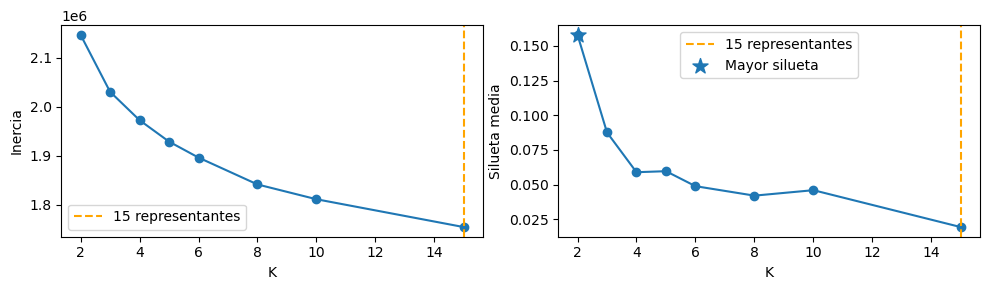

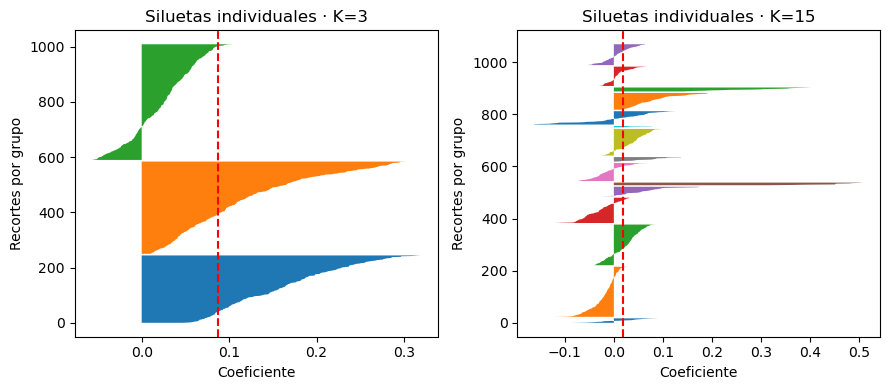

In [6]:
ks = [2,3,4,5,6,8,10,15]
inercias,siluetas,individuales = [],[],{}
for numero in ks:
    modelo = kmeans if numero==k else KMeans(n_clusters=numero,n_init=1,random_state=SEMILLA).fit(X_muestra)
    grupos = modelo.labels_
    valores = (silhouette_samples(X_muestra,grupos) if 1<len(set(grupos))<len(grupos)
               else np.full(len(grupos),np.nan))
    media = float(np.mean(valores))
    inercias.append(modelo.inertia_)
    siluetas.append(media)
    individuales[numero] = (grupos,valores)
    print(f"K={numero:2d}  inercia={modelo.inertia_:.2f}  silueta={media:.4f}")
fig,ejes = plt.subplots(1,2,figsize=(10,3))
for ax,serie,titulo in zip(ejes,[inercias,siluetas],["Inercia","Silueta media"]):
    ax.plot(ks,serie,"o-")
    ax.axvline(k,ls="--",color="orange",label="15 representantes")
    ax.set(xlabel="K",ylabel=titulo)
if np.isfinite(siluetas).any():
    j = np.nanargmax(siluetas)
    ejes[1].scatter(ks[j],siluetas[j],marker="*",s=130,label="Mayor silueta")
for ax in ejes: ax.legend()
plt.tight_layout()
plt.show()
fig,ejes = plt.subplots(1,2,figsize=(9,4))
for ax,numero in zip(ejes,[3,k]):
    grupos,valores = individuales[numero]
    base = 0
    for g in range(numero):
        v = np.sort(valores[grupos==g])
        ax.fill_betweenx(np.arange(base,base+len(v)),0,v)
        base += len(v)+5
    ax.axvline(np.mean(valores),color="red",ls="--")
    ax.set(title=f"Siluetas individuales · K={numero}",xlabel="Coeficiente",ylabel="Recortes por grupo")
plt.tight_layout()
plt.show()

## 7. Representantes y etiquetas humanas

0 suelo cuando domina tierra o piedra. 1 basura cuando el objeto principal son residuos reconocibles, incluso sobre tierra. 2 planta para vegetación dominante. Usa x para agua, otra categoría o una mezcla ambigua. La imagen que etiquetas conserva los tres canales.

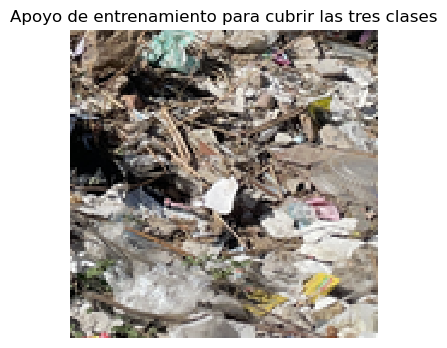

Grupos representados 10 apoyos 1 consultados 30
Etiquetas aceptadas Counter({0: 6, 2: 4, 1: 1})


In [7]:
orden_grupos = {}
fig, ejes = plt.subplots(3,5,figsize=(10,6))
for g,ax in enumerate(ejes.flat):
    miembros = np.flatnonzero(grupos_train == g)
    orden_grupos[g] = miembros[np.argsort(distancias[miembros,g], kind="stable")]
    ax.axis("off")
    if len(miembros):
        i = train[orden_grupos[g][0]]
        ax.imshow(imagenes[i])
        ax.set_title(f"Grupo {g} · n={len(miembros)}", fontsize=8)
fig.tight_layout()
plt.show()

anotaciones = {}
if ruta_etiquetas.exists():
    with ruta_etiquetas.open(encoding="utf-8-sig", newline="") as f:
        anotaciones = {r["ruta_recorte"]:r for r in csv.DictReader(f)}

def consultar(i, etapa):
    clave = filas[i]["ruta_recorte"]
    if clave not in anotaciones:
        clear_output(wait=True)
        plt.figure(figsize=(4,4))
        plt.imshow(imagenes[i],interpolation="nearest")
        plt.axis("off")
        plt.title(etapa)
        plt.show()
        plt.close()
        while True:
            tecla = input("0 suelo | 1 basura | 2 planta | x descartar | q pausar: ").strip().lower()
            if tecla == "q":
                raise RuntimeError("Pausa solicitada. Reejecuta esta celda de consulta para continuar.")
            if tecla in ["0","1","2","x"]: break
        anotaciones[clave] = dict(ruta_recorte=clave, etapa=etapa, codigo=tecla)
        escribir_csv(ruta_etiquetas, list(anotaciones.values()), ["ruta_recorte","etapa","codigo"])
    valor = anotaciones[clave]["codigo"]
    return -1 if valor == "x" else int(valor)

reps, apoyos, vistos = {}, {}, set()
for g, candidatos in orden_grupos.items():
    for pos in candidatos[:3]:
        i = train[pos]
        vistos.add(i)
        y = consultar(i, f"Representante del grupo {g}")
        if y >= 0:
            reps[g] = (i,y)
            break
humanas = dict(reps.values())
for i in np.random.RandomState(SEMILLA).permutation(train):
    if set(humanas.values()) == {0,1,2}: break
    if i in vistos: continue
    vistos.add(i)
    y = consultar(i, "Apoyo de entrenamiento para cubrir las tres clases")
    if y >= 0:
        apoyos[i] = y
        humanas[i] = y
if set(humanas.values()) != {0,1,2}:
    raise ValueError("Las tres clases deben existir en train. Revisa la definición usando entrenamiento.")
print("Grupos representados", len(reps), "apoyos", len(apoyos), "consultados", len(vistos))
print("Etiquetas aceptadas", Counter(humanas.values()))

## 8. Referencia humana de prueba

Se eligen 100 recortes reproducibles de test y se etiquetan sin observar predicciones. Se informa el soporte de cada clase y la cobertura de los aceptados. Si ya has analizado el test anterior, trata la comparación con ese test como exploratoria.

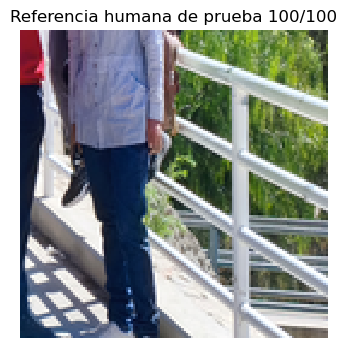

Test reservado 1808 revisados 100 aceptados 80 descartados 20 cobertura 80.0%
Soporte por clase {'suelo': 31, 'basura': 22, 'planta': 27}
Fotografías evaluadas 58


In [8]:
N_PRUEBA = 100
seleccion = np.random.RandomState(SEMILLA).permutation(test)
if N_PRUEBA is not None: seleccion = seleccion[:N_PRUEBA]
prueba = {}
for j,i in enumerate(seleccion,1):
    y = consultar(i, f"Referencia humana de prueba {j}/{len(seleccion)}")
    if y >= 0: prueba[i] = y
if not prueba: raise ValueError("La muestra de test no contiene recortes aceptados.")
y_test = np.array(list(prueba.values()))
X_test = vectores(list(prueba))
print("Test reservado", len(test), "revisados",len(seleccion), "aceptados",len(prueba),
      "descartados",len(seleccion)-len(prueba), "cobertura",f"{len(prueba)/len(seleccion):.1%}")
print("Soporte por clase", {c:int((y_test==j).sum()) for j,c in enumerate(CLASES)})
print("Fotografías evaluadas",len({filas[i]["ruta_original"] for i in prueba}))

## 9. Ajustar con representantes y comparar con selección aleatoria

Regresión logística uno contra el resto, como en el laboratorio. Ambos enfoques utilizan igual número de etiquetas humanas aceptadas. El control aleatorio se mantiene separado de la propagación.

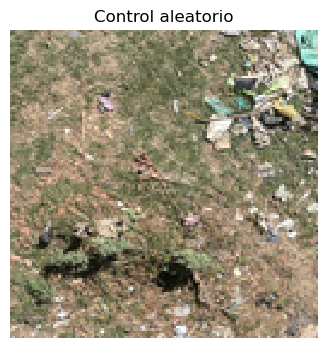

Control Counter({0: 5, 2: 4, 1: 2}) aceptados 11 consultados 12


In [9]:
def ajustar(ids, etiquetas):
    modelo = OneVsRestClassifier(LogisticRegression(solver="lbfgs", max_iter=5000, random_state=SEMILLA))
    return modelo.fit(vectores(list(ids)), np.asarray(list(etiquetas), dtype=int))

modelo_rep = ajustar(humanas.keys(), humanas.values())
control, vistos_control = {}, set()
disponibles = sorted(set(train) - vistos)
for i in np.random.RandomState(SEMILLA+1).permutation(disponibles):
    vistos_control.add(i)
    y = consultar(i, "Control aleatorio")
    if y >= 0: control[i] = y
    if len(control) == len(humanas): break
if len(control) != len(humanas):
    raise ValueError("No hay suficientes recortes distintos para igualar el presupuesto.")
if len(set(control.values())) == 1:
    modelo_random = None
else:
    modelo_random = ajustar(control.keys(), control.values())
print("Control", Counter(control.values()), "aceptados", len(control), "consultados", len(vistos_control))

## 10. Semisupervisado · propagación y ajuste

Cada grupo con representante aceptado transmite su etiqueta a sus miembros. Se ajusta la regresión con hasta 1 000 recortes, dando prioridad a etiquetas humanas. La distribución impresa permite detectar clases con escaso respaldo.

In [10]:
pseudo = {}
for pos,i in enumerate(train):
    g = grupos_train[pos]
    if g in reps and i not in vistos_control and i not in vistos:
        pseudo[i] = reps[g][1]
extras = np.random.RandomState(SEMILLA).permutation(sorted(pseudo))
n_extra = min(len(extras), max(0, 1000-len(humanas)))
ajuste_semi = {i:pseudo[i] for i in extras[:n_extra]}
ajuste_semi.update(humanas)
modelo_semi = ajustar(ajuste_semi.keys(), ajuste_semi.values())
print("Humanas", len(humanas), "pseudoetiquetas usadas", n_extra, "distribución", Counter(ajuste_semi.values()))

Humanas 11 pseudoetiquetas usadas 989 distribución Counter({0: 698, 2: 301, 1: 1})


## 11. Activo · consultar, corregir y reentrenar

Se consultan hasta 15 ejemplos pseudoetiquetados con menor confianza máxima. Una respuesta humana corrige o confirma la etiqueta. Un descarte retira el ejemplo del ajuste.

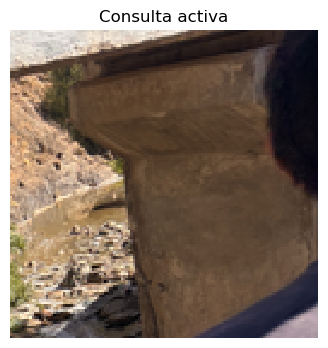

Consultas 15 descartes 7 etiquetas corregidas 4


In [11]:
candidatos = np.array(sorted(set(ajuste_semi)-set(humanas)), dtype=int)
if not len(candidatos):
    raise ValueError("Faltan ejemplos pseudoetiquetados para la consulta activa.")
confianza = np.concatenate([modelo_semi.predict_proba(vectores(lote)).max(axis=1)
                           for lote in np.array_split(candidatos, int(np.ceil(len(candidatos)/64)))])
orden = np.argsort(confianza, kind="stable")[:k]
ajuste_activo = ajuste_semi.copy()
auditoria = []
for pos in orden:
    i = candidatos[pos]
    y = consultar(i, "Consulta activa")
    anterior = ajuste_semi[i]
    if y == -1: ajuste_activo.pop(i)
    else: ajuste_activo[i] = y
    auditoria.append(dict(recorte=filas[i]["ruta_recorte"], confianza=confianza[pos],
                          pseudo=CLASES[anterior], humana="descartar" if y<0 else CLASES[y]))
modelo_activo = ajustar(ajuste_activo.keys(), ajuste_activo.values())
print("Consultas",len(auditoria), "descartes",sum(a["humana"]=="descartar" for a in auditoria),
      "etiquetas corregidas",sum(a["humana"] not in ["descartar",a["pseudo"]] for a in auditoria))

## 12. Evaluación de clasificación

La exactitud indica la proporción de aciertos sobre los recortes de prueba etiquetados a mano. En la matriz del modelo activo, cada fila muestra la clase real y cada columna la clase predicha. La diagonal cuenta los aciertos.

Representantes: 46.25%
Aleatorio: 57.50%
Semisupervisado: 27.50%
Activo: 33.75%


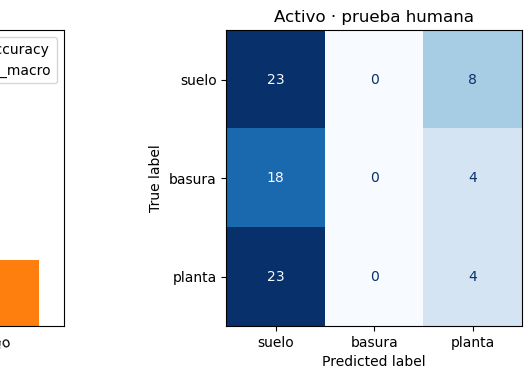

In [12]:
modelos = {"Representantes":modelo_rep, "Aleatorio":modelo_random,
           "Semisupervisado":modelo_semi, "Activo":modelo_activo}
for nombre, modelo in modelos.items():
    pred = modelo.predict(X_test) if modelo is not None else np.full(len(y_test),next(iter(control.values())))
    exactitud = accuracy_score(y_test, pred)
    print(f"{nombre}: {exactitud:.2%}")
pred_final = modelo_activo.predict(X_test)
ConfusionMatrixDisplay.from_predictions(y_test, pred_final, labels=[0, 1, 2],
    display_labels=CLASES, cmap="Blues", values_format="d", colorbar=False)
plt.title("Activo · prueba humana")
plt.tight_layout()
plt.show()

## 13. Clasificar un recorte nuevo

Con el kernel activo puedes llamar a la función con la ruta de un recorte nuevo. Se prepara con el mismo orden RGB que en el entrenamiento.

In [13]:
def clasificar_recorte(ruta):
    with Image.open(ruta) as original:
        rgb = ImageOps.exif_transpose(original).convert("RGB").resize((128,128),Image.Resampling.LANCZOS)
    x = np.asarray(rgb,dtype=np.float32).reshape(1,-1)/255
    return CLASES[int(modelo_activo.predict(x)[0])]
